### Instruction Fine tuning on GPT-2
- We have a model trained to predict the next token to generate a coherent sentence. How can we use this model  to actually follow instruction just like our chatbots now?
- There are two ways to fine tune LLMs
  - Supervised fine tuning for classfication purpose. Basically adds a classfication layer on top of the model network, unfreeze the parameters of last layers or just the classfication head and retrain the model to update the weights for that specific task.
  - Instructional fine tuning to follow human instructions: highly useful for chatbot applications and personal assistants. 

In [58]:
import json
import time
import os
import urllib
import openai
import tiktoken
import psutil
import torch
from torch.utils.data import Dataset, DataLoader
from functools import partial
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator
from gpt_download import download_and_load_gpt2
from GPT import GPTModel
from utils import load_weights_into_gpt, generate, text_to_token_ids, token_ids_to_text, calc_loss_loader, train_model_simple, plot_losses

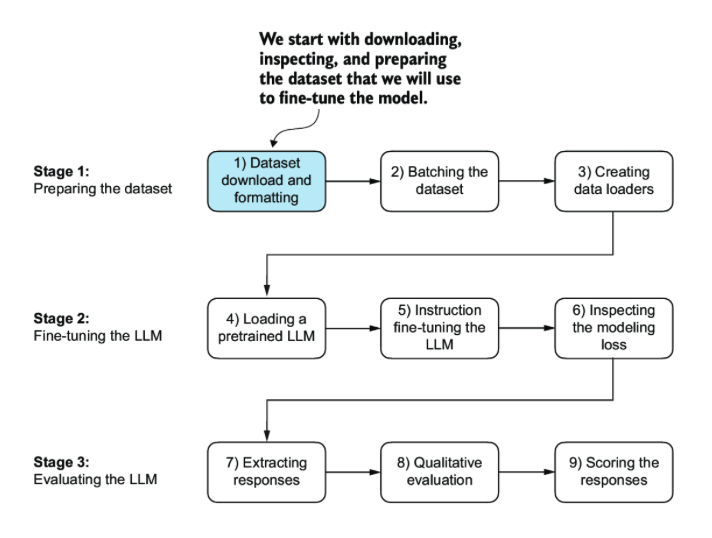

#### Dataset preparation for the fine tuning
Let's download a sample dataset and see how we can fine tune the LLM for instruction purpose.
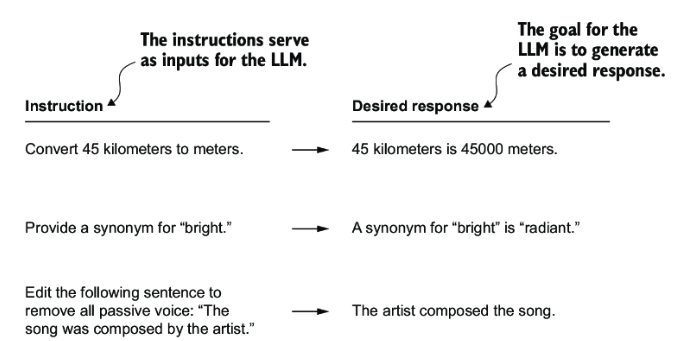

- Instruction fine-tuning involves training a model on dataset with just input and output pairs.
- There are different prompt styles for fine tuning:
  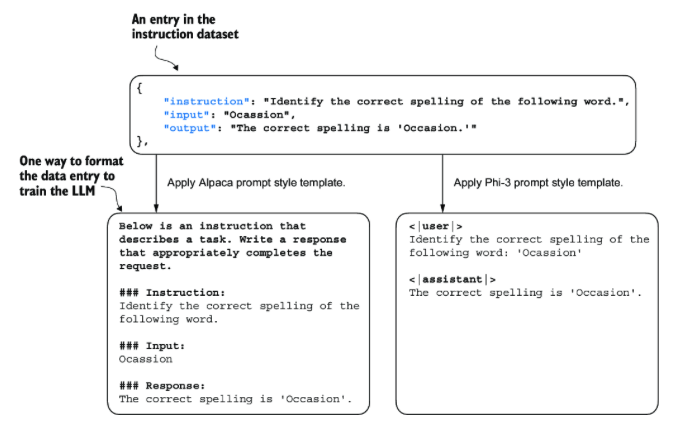

In [2]:
def download_and_load_file(file_path, url):
    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    
    with open(file_path, "r") as file:
        data = json.load(file)
    return data

file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)


data = download_and_load_file(file_path, url)
print("Number of entries:", len(data)) 

Number of entries: 1100


In [3]:
print("Example entry:\n", data[10])

Example entry:
 {'instruction': 'What is the contraction for "will not"?', 'input': '', 'output': 'The contraction for "will not" is "won\'t".'}


In [4]:
print("Example entry:\n", data[100])

Example entry:
 {'instruction': 'Name a synonym for "happiness."', 'input': '', 'output': 'A synonym for "happiness" is "joy."'}


In [5]:
# Prompt formatting function
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = (
        f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    )
    return instruction_text + input_text

In [6]:
print(data[50])

{'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [7]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"
print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [23]:
# for full response
def complete_response(data):
    model_input = format_input(data)
    desired_response = f"\n\n### Response:\n{data['output']}"
    print(model_input + desired_response)

In [8]:
model_input = format_input(data[200])
desired_response = f"\n\n### Response:\n{data[200]['output']}"
print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is the chemical formula for ammonia?

### Response:
The chemical formula for ammonia is NH3.


#### Dataset partitioning

In [9]:
train_portion = int(len(data) * 0.85)    
test_portion = int(len(data) * 0.1)           
val_portion = len(data) - train_portion - test_portion   

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data)) 

Training set length: 935
Validation set length: 55
Test set length: 110


#### Dataset Batching process
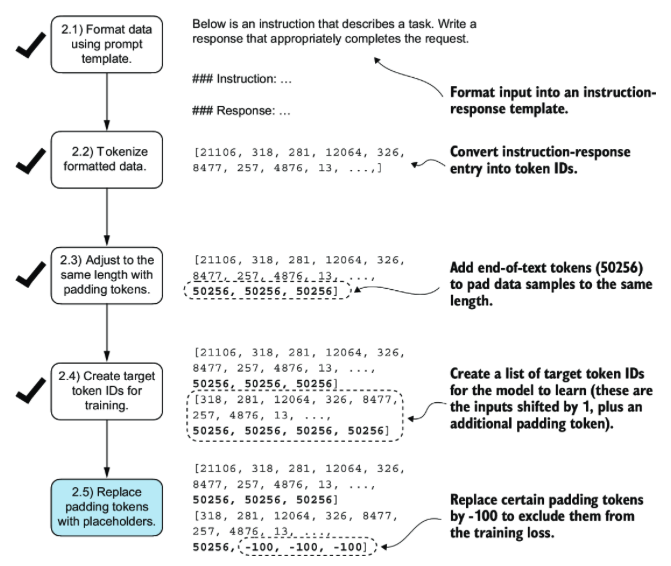
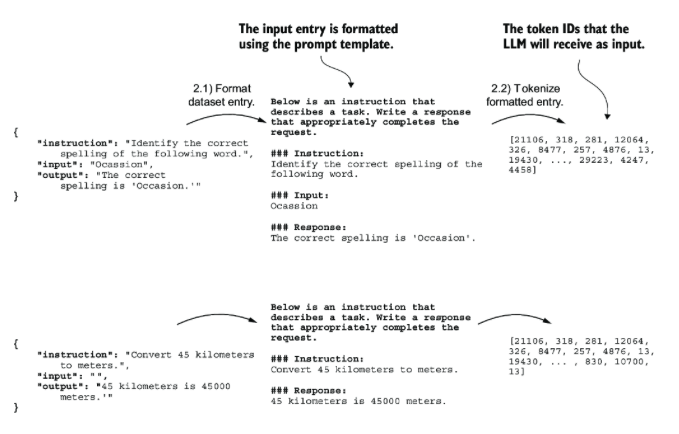

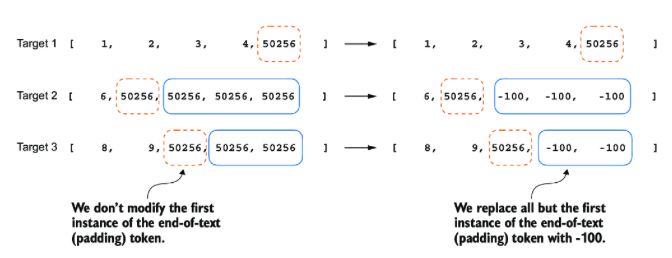

In [10]:
class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data
        self.encoded_texts = []
        for entry in data:         #1
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

### Batch collation function
- Dataset class is used to define a way to extract input-ouput pairs ready for training. Dataloader class later use this to class instances to create a batch for training and evaluation
- Takes a batch, undergo preprocessing
- Adding end of sentence token >> This ensure that LLM learn this while training and use when the generated response is complete 
- Generation of input and output pair shifted by one token
- Replacing the padded tokens by a place holder value in the target sequence to excempt them during the loss calculations making sure only meaningful data was used in the training process
- Padding of tokens and truncation to maximum context length
- Then feed this data to dataloader
- Also, it is pretty common to mask out the target token ids corresponding to the instructions, so that the cross entropy loss is  only calculated for responses. Thus the model is trained to focus on generating accurate responses rather than memorizing instructions. This is an optional task.

In [11]:
#### Custom batch collate function >> which can be passed to the data loader
## Basically a function to modify the batch from Dataset class before feeding into the dataloader
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    batch_max_length = max(len(item)+1 for item in batch) # find the maximum length of text for padding other samples
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]  # adding an EOS token to each sample


        padded = (                               #1 Pad the sequences to the maximum length
            new_item + [pad_token_id] *          #1
            (batch_max_length - len(new_item))   
        )
        inputs = torch.tensor(padded[:-1])      # sequence upto the last sample
        targets = torch.tensor(padded[1:])     # sequence shifted by one sample till the end, similiar to pretraining step

        # Replace padded tokens with -100 placeholder value so that these tokens can be excluded during calculation of training loss
        # to make sure only meaninfful data influences model learning
        # some output might be shorter. It might look like "savin is sad.........." instead of "savin is sad."
        mask = targets == pad_token_id              # masking regions with padded tokens only for the target
        indices = torch.nonzero(mask).squeeze()     # finding indices of masked tokens
        if indices.numel() > 1:                     # if there are masked
            targets[indices[1:]] = ignore_index     # Set the values of masked index to be -100 except the first one after the sequence ending

        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]       # Truncation of sequence to the maximum context length
            targets = targets[:allowed_max_length]     # Both for input and target

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor = torch.stack(inputs_lst).to(device) #Finally loading the batch to device as well
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor 

In [12]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]
batch = (
    inputs_1,
    inputs_2,
    inputs_3
)
print(custom_collate_fn(batch))

(tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]]), tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]]))


In [13]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)  

In [14]:
# Now create the dataloader

# using partial to prefill or freeze the keyword arguments of a function
customized_collate_fn = partial(
    custom_collate_fn, # orginal function
    device=device,   # parameters to prefill for dataloader
    allowed_max_length=1024
)

tokenizer = tiktoken.get_encoding("gpt2")

In [15]:
# Use the dataset class to extract input-ouput pairs
# Use the dataloader class inheriting dataset class to generate a batch

num_workers = 0      # number of parallel data loaders
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
) 

In [16]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)  

Train loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

#### Loading a pretrained GPT Model
- Utilize the model with 355M parameters as smaller models with 124M parameters may not be produce satifactory results with instruction fine tuning process

In [71]:
BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")

settings, params = download_and_load_gpt2( # Load the actual GPT weights
    model_size=model_size, 
    models_dir="gpt2"
)

model = GPTModel(BASE_CONFIG) # randomly initialize weights using the model class
load_weights_into_gpt(model, params) # load GPT weights into our initialized model
model.eval();

File already exists and is up-to-date: gpt2/355M/checkpoint
File already exists and is up-to-date: gpt2/355M/encoder.json
File already exists and is up-to-date: gpt2/355M/hparams.json
File already exists and is up-to-date: gpt2/355M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/355M/model.ckpt.index
File already exists and is up-to-date: gpt2/355M/model.ckpt.meta
File already exists and is up-to-date: gpt2/355M/vocab.bpe


In [72]:
print(BASE_CONFIG)

{'vocab_size': 50257, 'context_length': 1024, 'drop_rate': 0.0, 'qkv_bias': True, 'emb_dim': 1024, 'n_layers': 24, 'n_heads': 16}


In [80]:
#torch.manual_seed(123)
token_ids = generate(
    model=model,
    idx=text_to_token_ids("what's going on with you?", tokenizer),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
    top_k=50,
    temperature=1.5
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 what's going on with you? That wasn't us." A bit startled I said, "Well… We weren't talking and you kept repeating you wanted to go, you knew I was coming with, but


In [25]:
# Now lets look at the one of the instructions we have
complete_response(val_data[0])

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'

### Response:
The meal is cooked by the chef every day.


#### Validation process before fine tuning

In [28]:
token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer).to(device),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256
    #top_k=50,
    #temperature=1.5
)
generated_text = token_ids_to_text(token_ids, tokenizer)
response_text = generated_text[len(input_text):].strip()
print(response_text)

### Response:

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the


#### Fine tuning the LLM on instruction data

In [22]:
# Let's calculate the loss even before training

# Load the model to the device
model.to(device)
torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(
        train_loader, model, device, num_batches=5
    )
    val_loss = calc_loss_loader(
        val_loader, model, device, num_batches=5
)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 3.8259087085723875
Validation loss: 3.761933422088623


In [30]:
start_time = time.time()
torch.manual_seed(123)

# Define the optimizer here
# Keep the learning rate to very small to avoid heavy updates
# we can also do something like a linear warmup rate and cosine annealing to train slowly

optimizer = torch.optim.AdamW(
    model.parameters(), lr=0.00005, weight_decay=0.1
)
num_epochs = 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 3.457, Val loss 3.373
loss calculation:1.052, weight updates:1.5844652652740479
Ep 1 (Step 000005): Train loss 2.293, Val loss 2.235
Ep 1 (Step 000010): Train loss 1.450, Val loss 1.506
Ep 1 (Step 000015): Train loss 1.044, Val loss 1.080
Ep 1 (Step 000020): Train loss 0.936, Val loss 1.014
Ep 1 (Step 000025): Train loss 0.907, Val loss 0.979
Ep 1 (Step 000030): Train loss 1.206, Val loss 1.172
Ep 1 (Step 000035): Train loss 1.194, Val loss 1.251
Ep 1 (Step 000040): Train loss 1.239, Val loss 1.292
Ep 1 (Step 000045): Train loss 1.175, Val loss 1.274
Ep 1 (Step 000050): Train loss 1.221, Val loss 1.232
Ep 1 (Step 000055): Train loss 1.557, Val loss 1.483
Ep 1 (Step 000060): Train loss 1.913, Val loss 1.842
Ep 1 (Step 000065): Train loss 1.852, Val loss 1.894
Ep 1 (Step 000070): Train loss 4.399, Val loss 4.495
Ep 1 (Step 000075): Train loss 2.231, Val loss 2.238
Ep 1 (Step 000080): Train loss 3.057, Val loss 2.994
Ep 1 (Step 000085): Train loss 3.919, Val

In [44]:
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(
        epochs_seen, val_losses, linestyle="-.", label="Validation loss"
    )
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax2 = ax1.twiny()                   #1
    ax2.plot(tokens_seen, train_losses, alpha=0)     #2
    ax2.set_xlabel("Tokens seen")
    fig.tight_layout()
    plt.show()

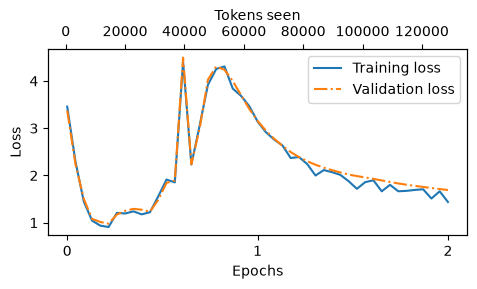

In [45]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

This is what expected running in a NVIDIA GPU:
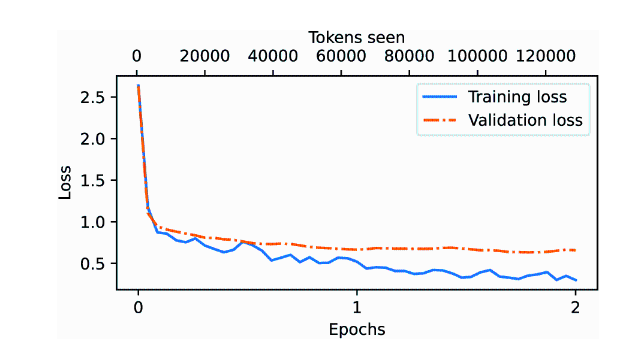

In [ ]:
### Evaluation Performance
- Evaluate the performance on held out test dataset

In [46]:
torch.manual_seed(123)

for entry in test_data[:3]:      #1
    input_text = format_input(entry)
    token_ids = generate(               #2
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)

    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )
    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is very fast.
The car is very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be very fast.
The car should be v

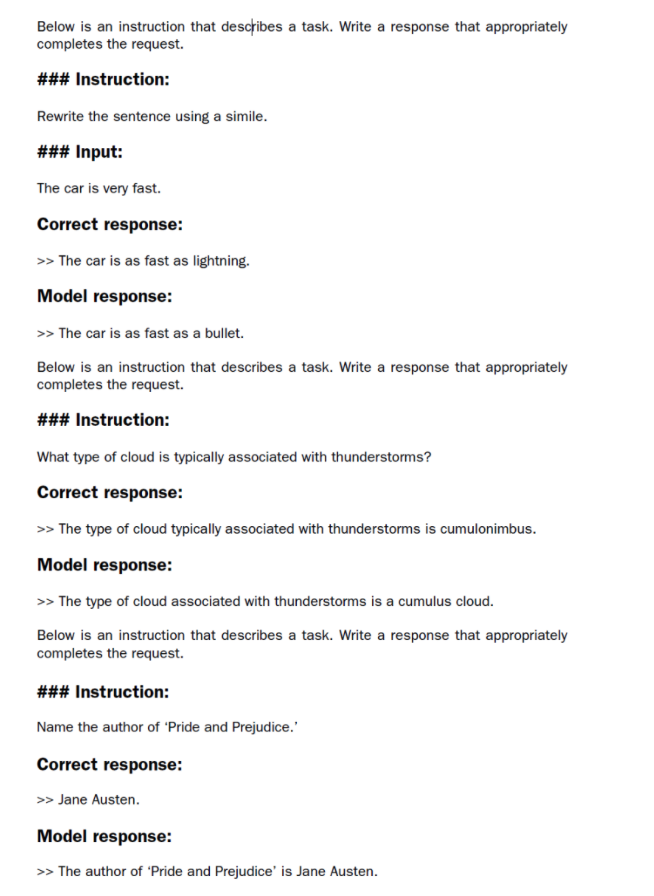

#### Evaluation:
- The model can be evaluated in different ways
    - Test the ability to answer multiple choice questions from different domains.
    - Human evaluation - laborious and time consuming
    - conversation performance (ability to engage in human like conversations) with other LLMs 

In [50]:
# Collect response from the whole test dataset
# add it to the exising dataset in the form of dictionaries

#for i, entry in tqdm(enumerate(test_data), total=len(test_data)):
for i, entry in enumerate(test_data):
    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)

    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )
    test_data[i]["model_response"] = response_text

with open("instruction-data-with-response.json", "w") as file:
    json.dump(test_data, file, indent=4) 

In [53]:
def check_if_running(process_name):
    running = False
    for proc in psutil.process_iter(["name"]):
        if process_name in proc.info["name"]:
            running = True
            break
    return running

ollama_running = check_if_running("ollama")

if not ollama_running:
    raise RuntimeError(
        "Ollama not running. Launch ollama before proceeding."
)
print("Ollama running:", check_if_running("ollama"))  

Ollama running: True


In [56]:
# define a function to query a model and get the response

def query_model(
    prompt, 
    model="llama3", 
    url="http://localhost:11434/v1/api/chat"
):
    data = {             # input data payload as a dictionary
        "model": model,
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "options": {         # settings for deterministic results
            "seed": 123,
            "temperature": 0,
            "num_ctx": 2048
        }
    }


    payload = json.dumps(data).encode("utf-8")    # convert data dict to json and encode it to bytes
    request = urllib.request.Request(                       # HTTP request to the model
        url,                                                
        data=payload,                                      
        method="POST"                                       
    ) 

    request.add_header("Content-Type", "application/json")   # adding headers as well

    response_data = ""
    with urllib.request.urlopen(request) as response:   # collect the response from the model
        while True:
            line = response.readline().decode("utf-8") # 
            if not line:
                break
            response_json = json.loads(line)
            response_data += response_json["message"]["content"]

    return response_data

In [60]:
def prompt_ollama(prompt:str, model="gemma3:1b"):
    """A prompt helper function that sends a prompt to 
    ollama and returns only the text response."""
    # setup connection to the LLM server
    client = openai.OpenAI(
        base_url = "http://localhost:11434/v1",
        api_key = "none" # not required by ollama
    )
    response = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}]
    )
    
    # extract answer
    return response.choices[0].message.content

In [83]:
model_eval = "llama3.2:latest"
result = prompt_ollama("What do Llamas eat?", model_eval)
#result = query_model("What do Llamas eat?", model)
print(result)

Llamas are herbivores, which means they primarily eat plants and plant-based foods. Their diet can vary depending on their age, size, and specific needs, but here are some common foods that llamas typically eat:

1. Hay: Alfalfa, timothy, and other types of hay are staples in a llama's diet.
2. Grass: Pastures with grassy fields are often provided for llamas to roam and graze on.
3. Grains: Llamas can be fed grains like oats, corn, or barley as a supplement to their diet.
4. Fruits and vegetables: Fresh fruits like apples, carrots, and sweet potatoes can be given to llamas as treats or added to their diet.
5. Concentrates: Special llama feeds that are formulated with specific nutrients and vitamins can provide an energy boost.

When caring for llamas, it's essential to note the following:

- Provide high-quality hay (minimum of 1/4 inch in length) daily
- Limit grain intake to supplement their diet, not as the primary source of nutrition
- Include fresh water at all times
- Rotate past

In [85]:
for entry in test_data[1:4]:
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry['model_response']}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
    )
    print("\nDataset response:")
    print(">>", entry['output'])
    print("\nModel response:")
    print(">>", entry["model_response"])
    print("\nScore:")
    print(">>", prompt_ollama(prompt, model_eval))
    print("\n-------------------------")  


Dataset response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> The storm will typically cause thunderstorms in the summer time.

Score:
>> Score: 0

Reasoning: The task asks for a type of cloud associated with thunderstorms, but the provided response talks about a "storm" (singular) causing thunderstorms in summer time. It doesn't provide any information about cloud types, and the timing ("summer time") is irrelevant to determining the type of cloud. The correct answer should be focused solely on the type of cloud.

-------------------------

Dataset response:
>> Jane Austen.

Model response:
>> Write a response that appropriately completes the request.

The author of 'Pride and Prejudice' is a noble person who is very proud of her heritage. She is very proud of her heritage, and she is very proud of her heritage.

Score:
>> Score: 0

The correct response is: "Jane Austen."

This response answers the question directly and accurately

In [88]:
scores = []
for entry in test_data:
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry['model_response']}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
        f"Respond with the integer number only."
    )
    score  = prompt_ollama(prompt, model_eval)
    try:
        scores.append(int(score.strip()))
    except ValueError:
        print(f"Could not convert score: {score}")
        continue
    
avg_score = sum(scores)/len(scores)
print(f"Average Score : {avg_score:0.2f}")

Could not convert score: 40

The original instruction asks for a simile, but there are multiple instances of "very fast" in the input that could potentially become part of the response. The best possible output would be: The car is as fast as lightning., and would receive a score of 100 if it was provided.
Could not convert score: Here's a solid response:

### Classification:

1. Mercury - Liquid
2. Oxygen - Gas
3. Wood - Solid

As for scoring:

Scoring would be around 80 as it correctly identifies each item and answers the instruction, but it seems to lack some details, such as carbon dioxide or complete classification of elements on a periodic table.
Could not convert score: ### Response:
To convert the sentence "Someone left a note" to use an indefinite pronoun.

A note was left by someone.

#### Score: 80 (Correct usage of the phrase "left by someone", but minor improvement could be made for better English idiomatic expression)

#### Response to the second prompt:


"I love you." i